# k-NN V8

For this experiment, I wanted to see if the best k values changed when using more training samples. I tested the same k values as V2, but this time with 8000 training samples and the full validation set for each dataset.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys

import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data_loader import load_task, split_train_val
from src.models.knn import KNNClassifier, euclidean_distance

k_values = [1, 3, 5, 10, 20]


I started by testing the different k values on the image dataset.

In [2]:
X, y, image_X_test, image_test_ids = load_task("image")
X_train, image_X_val, y_train, image_y_val = split_train_val(
    X, y, val_fraction=0.2, seed=42
)
image_X_train = X_train[:8000]
image_y_train = y_train[:8000]
assert len(image_X_train) == 8000
assert len(image_X_val) == 4000

result_dir = project_root / "results" / "image"
v7_summary = pd.read_csv(result_dir / "knn_v7_summary.csv")
image_v7_model = v7_summary.loc[v7_summary["training_samples"] == 8000].iloc[0]
image_v7_k = int(image_v7_model["k"])
v7_validation = pd.read_csv(result_dir / "knn_v7_validation.csv")
assert image_v7_k == 1
assert v7_validation["validation_index"].tolist() == list(range(4000))
assert v7_validation["actual_label"].tolist() == image_y_val.tolist()

image_rows = []
image_validation_predictions = {}
image_best_accuracy = -1
print("Image: 8000 training samples, 4000 validation samples")
for k in k_values:
    clf = KNNClassifier(k=k, distance_fn=euclidean_distance, voting_method="majority")
    clf.fit(image_X_train, image_y_train)
    start = perf_counter()
    y_pred = clf.predict(image_X_val)
    prediction_time = perf_counter() - start
    accuracy = sum(p == t for p, t in zip(y_pred, image_y_val)) / len(image_y_val)
    image_validation_predictions[k] = y_pred

    if k == image_v7_k:
        assert abs(accuracy - 0.39625) <= 1e-15
        assert abs(accuracy - image_v7_model["validation_accuracy"]) <= 1e-15
        assert y_pred == v7_validation["predicted_label"].tolist()
        print("V7 baseline accuracy and predictions reproduced exactly.")

    image_rows.append({
        "dataset": "image",
        "version": "V8",
        "k": k,
        "distance_metric": "euclidean",
        "voting_method": "majority",
        "normalized": False,
        "training_samples": len(image_X_train),
        "validation_samples": len(image_X_val),
        "validation_accuracy": accuracy,
        "prediction_time_seconds": prediction_time,
    })
    print(f"k={k:2d}  accuracy={accuracy:.4%}  prediction time={prediction_time:.6f} s")

    # k values are ascending, so the smaller k wins an accuracy tie.
    if accuracy > image_best_accuracy:
        image_best_k = k
        image_best_accuracy = accuracy

image_summary = pd.DataFrame(image_rows)
image_summary.to_csv(result_dir / "knn_v8_summary.csv", index=False)
pd.DataFrame({
    "validation_index": range(len(image_y_val)),
    "actual_label": image_y_val,
    "predicted_label": image_validation_predictions[image_best_k],
}).to_csv(result_dir / "knn_v8_validation.csv", index=False)
print(f"Selected k: {image_best_k}, accuracy={image_best_accuracy:.4%}")


Image: 8000 training samples, 4000 validation samples
V7 baseline accuracy and predictions reproduced exactly.
k= 1  accuracy=39.6250%  prediction time=149.383006 s
k= 3  accuracy=39.1750%  prediction time=160.467547 s
k= 5  accuracy=37.4750%  prediction time=1047.896735 s
k=10  accuracy=33.4750%  prediction time=151.111062 s
k=20  accuracy=30.6750%  prediction time=216.499218 s
Selected k: 1, accuracy=39.6250%


Then I repeated the same test with the sentiment dataset.

In [3]:
X, y, sentiment_X_test, sentiment_test_ids = load_task("sentiment")
X_train, sentiment_X_val, y_train, sentiment_y_val = split_train_val(
    X, y, val_fraction=0.2, seed=42
)
sentiment_X_train = X_train[:8000]
sentiment_y_train = y_train[:8000]
assert len(sentiment_X_train) == 8000
assert len(sentiment_X_val) == 2400

result_dir = project_root / "results" / "sentiment"
v7_summary = pd.read_csv(result_dir / "knn_v7_summary.csv")
sentiment_v7_model = v7_summary.loc[v7_summary["training_samples"] == 8000].iloc[0]
sentiment_v7_k = int(sentiment_v7_model["k"])
v7_validation = pd.read_csv(result_dir / "knn_v7_validation.csv")
assert sentiment_v7_k == 3
assert v7_validation["validation_index"].tolist() == list(range(2400))
assert v7_validation["actual_label"].tolist() == sentiment_y_val.tolist()

sentiment_rows = []
sentiment_validation_predictions = {}
sentiment_best_accuracy = -1
print("Sentiment: 8000 training samples, 2400 validation samples")
for k in k_values:
    clf = KNNClassifier(k=k, distance_fn=euclidean_distance, voting_method="majority")
    clf.fit(sentiment_X_train, sentiment_y_train)
    start = perf_counter()
    y_pred = clf.predict(sentiment_X_val)
    prediction_time = perf_counter() - start
    accuracy = sum(p == t for p, t in zip(y_pred, sentiment_y_val)) / len(sentiment_y_val)
    sentiment_validation_predictions[k] = y_pred

    if k == sentiment_v7_k:
        assert abs(accuracy - 0.5066666666666667) <= 1e-15
        assert abs(accuracy - sentiment_v7_model["validation_accuracy"]) <= 1e-15
        assert y_pred == v7_validation["predicted_label"].tolist()
        print("V7 baseline accuracy and predictions reproduced exactly.")

    sentiment_rows.append({
        "dataset": "sentiment",
        "version": "V8",
        "k": k,
        "distance_metric": "euclidean",
        "voting_method": "majority",
        "normalized": False,
        "training_samples": len(sentiment_X_train),
        "validation_samples": len(sentiment_X_val),
        "validation_accuracy": accuracy,
        "prediction_time_seconds": prediction_time,
    })
    print(f"k={k:2d}  accuracy={accuracy:.4%}  prediction time={prediction_time:.6f} s")

    # k values are ascending, so the smaller k wins an accuracy tie.
    if accuracy > sentiment_best_accuracy:
        sentiment_best_k = k
        sentiment_best_accuracy = accuracy

sentiment_summary = pd.DataFrame(sentiment_rows)
sentiment_summary.to_csv(result_dir / "knn_v8_summary.csv", index=False)
pd.DataFrame({
    "validation_index": range(len(sentiment_y_val)),
    "actual_label": sentiment_y_val,
    "predicted_label": sentiment_validation_predictions[sentiment_best_k],
}).to_csv(result_dir / "knn_v8_validation.csv", index=False)
print(f"Selected k: {sentiment_best_k}, accuracy={sentiment_best_accuracy:.4%}")


Sentiment: 8000 training samples, 2400 validation samples
k= 1  accuracy=48.6250%  prediction time=208.548057 s
V7 baseline accuracy and predictions reproduced exactly.
k= 3  accuracy=50.6667%  prediction time=216.369264 s
k= 5  accuracy=52.9583%  prediction time=216.350129 s
k=10  accuracy=54.3333%  prediction time=215.837885 s
k=20  accuracy=56.2917%  prediction time=219.524453 s
Selected k: 20, accuracy=56.2917%


I plotted the accuracies to compare how the results change with k.

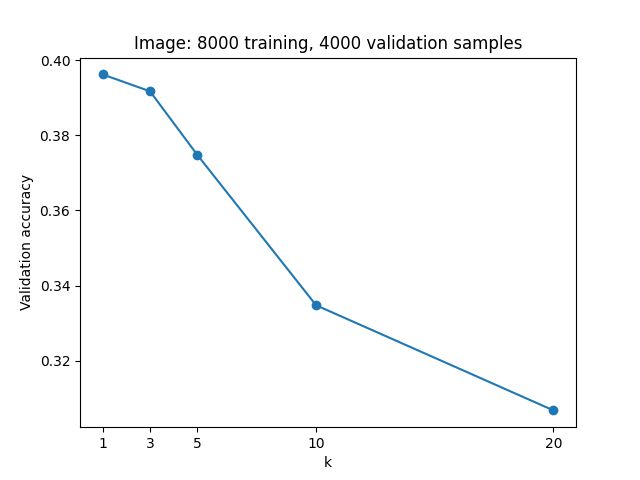

In [4]:
knn_result_dir = project_root / "results" / "knn"
knn_result_dir.mkdir(parents=True, exist_ok=True)
plt.figure()
plt.plot(image_summary["k"], image_summary["validation_accuracy"], marker="o")
plt.xlabel("k")
plt.ylabel("Validation accuracy")
plt.title("Image: 8000 training, 4000 validation samples")
plt.xticks(k_values)
plt.savefig(knn_result_dir / "knn_v8_image_accuracy.png")
plt.show()


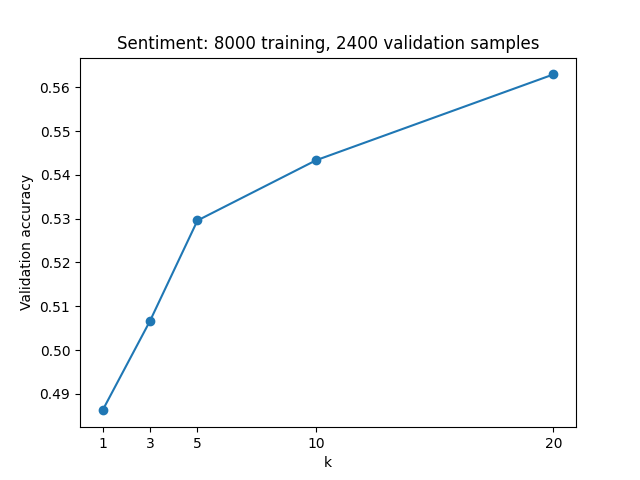

In [5]:
knn_result_dir = project_root / "results" / "knn"
knn_result_dir.mkdir(parents=True, exist_ok=True)
plt.figure()
plt.plot(sentiment_summary["k"], sentiment_summary["validation_accuracy"], marker="o")
plt.xlabel("k")
plt.ylabel("Validation accuracy")
plt.title("Sentiment: 8000 training, 2400 validation samples")
plt.xticks(k_values)
plt.savefig(knn_result_dir / "knn_v8_sentiment_accuracy.png")
plt.show()


Finally, I compared the results to choose the best k for each dataset.

In [6]:
for dataset, previous, selected_k, selected_accuracy in [
    ("Image", image_v7_model, image_best_k, image_best_accuracy),
    ("Sentiment", sentiment_v7_model, sentiment_best_k, sentiment_best_accuracy),
]:
    previous_k = int(previous["k"])
    print(dataset)
    print(f"V7: k={previous_k}, accuracy={previous['validation_accuracy']:.4%}")
    print(f"V8: k={selected_k}, accuracy={selected_accuracy:.4%}")
    print(f"Selected k changed: {previous_k != selected_k}")


Image
V7: k=1, accuracy=39.6250%
V8: k=1, accuracy=39.6250%
Selected k changed: False
Sentiment
V7: k=3, accuracy=50.6667%
V8: k=20, accuracy=56.2917%
Selected k changed: True


I used the best k values to predict the test labels.

In [7]:
assert image_v7_model["training_samples"] == 8000
assert image_v7_model["distance_metric"] == "euclidean"
assert image_v7_model["voting_method"] == "majority"
assert not image_v7_model["normalized"]
if image_best_k == image_v7_k:
    v7_submission = pd.read_csv(project_root / "submission" / "knn" / "submission_v7_knn.csv")
    assert v7_submission.columns.tolist() == ["id", "label"]
    assert len(v7_submission) == 10000 and v7_submission["id"].is_unique
    previous_predictions = pd.DataFrame({"id": image_test_ids}).merge(
        v7_submission, on="id", how="left", sort=False
    )
    assert not previous_predictions.isna().any().any()
    image_test_predictions = previous_predictions["label"].tolist()
    print("Reused V7 image predictions: the selected k and all other model settings are identical.")
else:
    image_clf = KNNClassifier(
        k=image_best_k, distance_fn=euclidean_distance, voting_method="majority"
    )
    image_clf.fit(image_X_train, image_y_train)
    start = perf_counter()
    image_test_predictions = image_clf.predict(image_X_test)
    print(f"Image: predicted {len(image_test_predictions)} test labels in {perf_counter() - start:.2f} s")


Reused V7 image predictions: the selected k and all other model settings are identical.


In [8]:
assert sentiment_v7_model["training_samples"] == 8000
assert sentiment_v7_model["distance_metric"] == "euclidean"
assert sentiment_v7_model["voting_method"] == "majority"
assert not sentiment_v7_model["normalized"]
if sentiment_best_k == sentiment_v7_k:
    v7_submission = pd.read_csv(project_root / "submission" / "knn" / "submission_v7_knn.csv")
    assert v7_submission.columns.tolist() == ["id", "label"]
    assert len(v7_submission) == 10000 and v7_submission["id"].is_unique
    previous_predictions = pd.DataFrame({"id": sentiment_test_ids}).merge(
        v7_submission, on="id", how="left", sort=False
    )
    assert not previous_predictions.isna().any().any()
    sentiment_test_predictions = previous_predictions["label"].tolist()
    print("Reused V7 sentiment predictions: the selected k and all other model settings are identical.")
else:
    sentiment_clf = KNNClassifier(
        k=sentiment_best_k, distance_fn=euclidean_distance, voting_method="majority"
    )
    sentiment_clf.fit(sentiment_X_train, sentiment_y_train)
    start = perf_counter()
    sentiment_test_predictions = sentiment_clf.predict(sentiment_X_test)
    print(f"Sentiment: predicted {len(sentiment_test_predictions)} test labels in {perf_counter() - start:.2f} s")


Sentiment: predicted 5000 test labels in 484.61 s


In [9]:
image_predictions = pd.DataFrame({"id": image_test_ids, "label": image_test_predictions})
sentiment_predictions = pd.DataFrame({"id": sentiment_test_ids, "label": sentiment_test_predictions})
assert len(image_predictions) == 5000 and len(sentiment_predictions) == 5000
assert image_predictions["label"].between(0, 49).all()
assert sentiment_predictions["label"].between(0, 2).all()

predictions = pd.concat([image_predictions, sentiment_predictions], ignore_index=True)
sample_submission = pd.read_csv(project_root / "data" / "raw" / "sample_submission.csv")
assert len(predictions) == 10000 and len(sample_submission) == 10000
assert predictions["id"].is_unique and sample_submission["id"].is_unique
assert set(predictions["id"]) == set(sample_submission["id"])

# A left merge keeps the sample submission's ID order.
submission = sample_submission[["id"]].merge(predictions, on="id", how="left", sort=False)
assert submission.columns.tolist() == ["id", "label"]
assert submission["id"].tolist() == sample_submission["id"].tolist()
assert not submission.isna().any().any()
assert pd.api.types.is_integer_dtype(submission["label"])

submission_dir = project_root / "submission" / "knn"
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / "submission_v8_knn.csv"
submission.to_csv(submission_path, index=False)
saved_submission = pd.read_csv(submission_path)
assert pd.api.types.is_integer_dtype(saved_submission["label"])
pd.testing.assert_frame_equal(saved_submission, submission, check_dtype=False)
print("Saved and checked 10000 predictions in", submission_path)

v7_submission = pd.read_csv(submission_dir / "submission_v7_knn.csv")
assert saved_submission["id"].tolist() == v7_submission["id"].tolist()
changed = saved_submission["label"] != v7_submission["label"]
changed_predictions = int(changed.sum())
changed_image_predictions = int((changed & saved_submission["id"].isin(image_test_ids)).sum())
changed_sentiment_predictions = int((changed & saved_submission["id"].isin(sentiment_test_ids)).sum())
assert changed_predictions == changed_image_predictions + changed_sentiment_predictions
print(f"CSV identical to V7: {saved_submission.equals(v7_submission)}")
print(f"Changed predictions compared with V7: {changed_predictions}")
print(f"Changed image predictions: {changed_image_predictions}")
print(f"Changed sentiment predictions: {changed_sentiment_predictions}")
if image_best_k == image_v7_k and sentiment_best_k == sentiment_v7_k:
    pd.testing.assert_frame_equal(saved_submission, v7_submission, check_dtype=False)


Saved and checked 10000 predictions in C:\Users\user\OneDrive\Documentos\Fall2026\COMP472\team_project\COMP472\submission\knn\submission_v8_knn.csv
CSV identical to V7: False
Changed predictions compared with V7: 1499
Changed image predictions: 0
Changed sentiment predictions: 1499


In [10]:
tracker_path = knn_result_dir / "kaggle_scores.csv"
tracker = pd.read_csv(tracker_path, dtype=str, keep_default_na=False)
assert tracker["version"].is_unique
v8_row = {
    "version": "V8",
    "image_validation_accuracy": image_best_accuracy,
    "sentiment_validation_accuracy": sentiment_best_accuracy,
    "kaggle_public_score": "",
    "submitted_to_kaggle": False,
    "submission_filename": submission_path.name,
    "notes": f"8000 training samples and full validation; selected image k={image_best_k}, sentiment k={sentiment_best_k}.",
}
matching = tracker["version"] == "V8"
if matching.any():
    # Preserve any recorded Kaggle score and status on reruns.
    for column in ("image_validation_accuracy", "sentiment_validation_accuracy", "submission_filename", "notes"):
        tracker.loc[matching, column] = v8_row[column]
else:
    tracker = pd.concat([tracker, pd.DataFrame([v8_row])], ignore_index=True)
assert tracker["version"].is_unique
tracker.to_csv(tracker_path, index=False)
print(tracker.to_string(index=False))


version image_validation_accuracy sentiment_validation_accuracy kaggle_public_score submitted_to_kaggle   submission_filename                                                                                                notes
     V1                      0.21                         0.575                                   False                                                                                k=3 and 1,000 training samples per dataset.
     V2                     0.215                         0.575               0.329                True submission_v2_knn.csv                                             Tested k=1, 3, 5, 10, 20; best image k=1, sentiment k=3.
     V3                     0.215                         0.575                                   False submission_v3_knn.csv      Compared Euclidean, Manhattan, Minkowski p=3; best image: Euclidean; best sentiment: Euclidean.
     V4                     0.215                         0.575                             